IMPORT LIBRARIES

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor as GradientBoost
from sklearn.svm import SVR
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.datasets import fetch_california_housing

LOAD DATASET AND CONVERT TO DATAFRAME

In [63]:
ch=fetch_california_housing()
df=pd.DataFrame(ch.data,columns=ch.feature_names)
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


INFORMATION ABOUT DATA

In [64]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


COUNDING NULL VALUES

In [65]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


The given data has no null values,Therefor no imputation is performing

CHECK DUPLICATES

In [ ]:
df.duplicated().sum()

np.int64(0)

no duplicates found

OUTLIER DETECTION

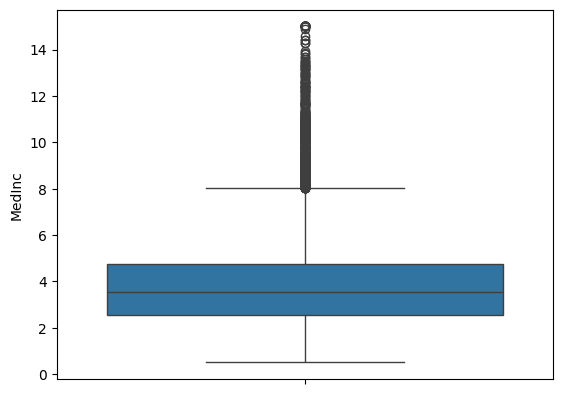

In [ ]:
sns.boxplot(df['MedInc'])
plt.show()

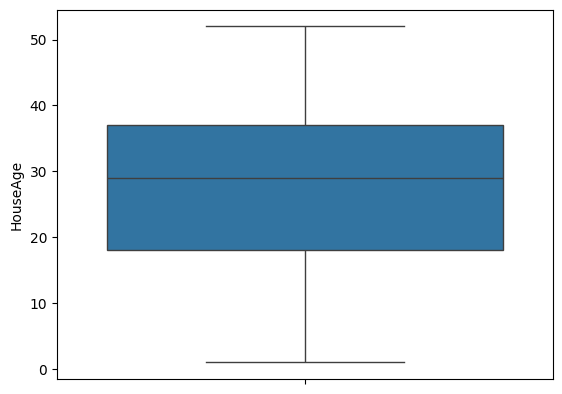

In [ ]:
sns.boxplot(df['HouseAge'])
plt.show()

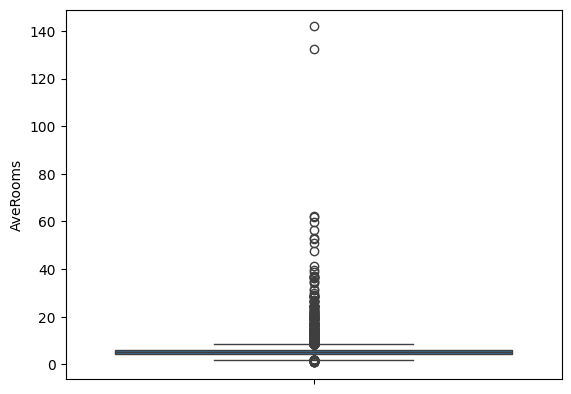

In [ ]:
sns.boxplot(df['AveRooms'])
plt.show()

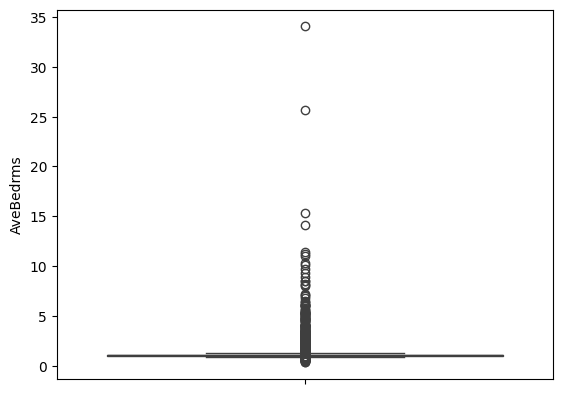

In [ ]:
sns.boxplot(df['AveBedrms'])
plt.show()

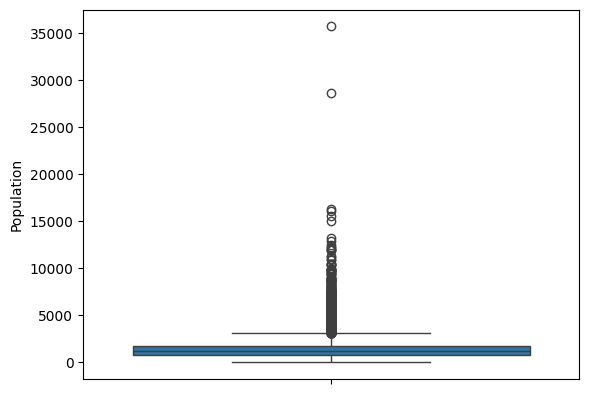

In [ ]:
sns.boxplot(df['Population'])
plt.show()

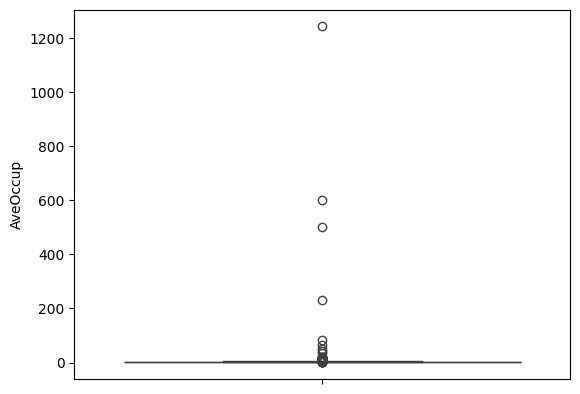

In [ ]:
sns.boxplot(df['AveOccup'])
plt.show()

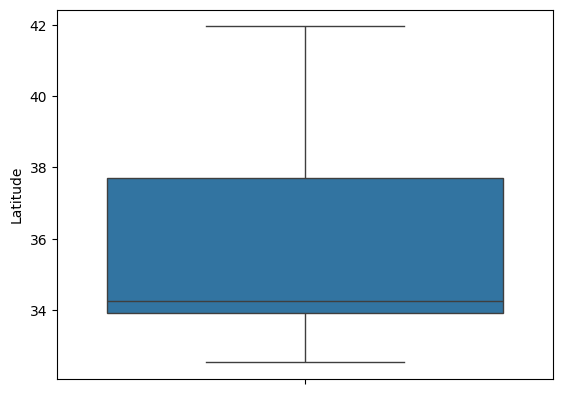

In [ ]:
sns.boxplot(df['Latitude'])
plt.show()

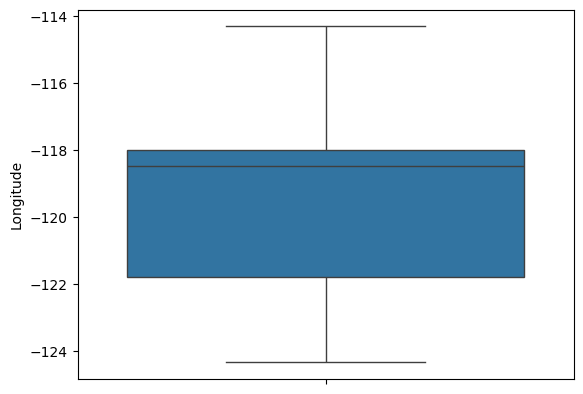

In [ ]:
sns.boxplot(df['Longitude'])
plt.show()

OUTLIER REMOVAL

In [ ]:
Q1=df.quantile(0.25)
Q2=df.quantile(0.75)
Q3=Q2-Q1
lower_limit=Q1-1.5*Q3
upper_limit=Q2+1.5*Q3
IQR_cleaned_data=df[(df>=lower_limit)&(df<=upper_limit)]


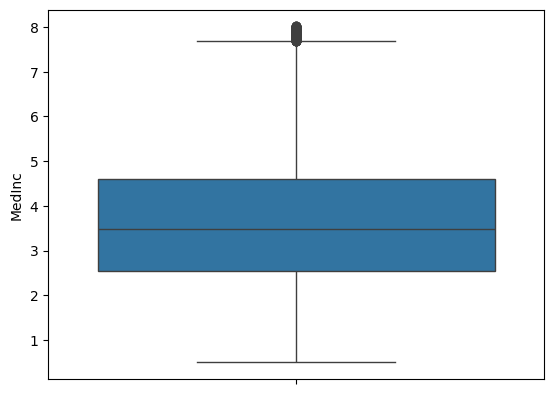

In [ ]:
sns.boxplot(IQR_cleaned_data['MedInc'])
plt.show()

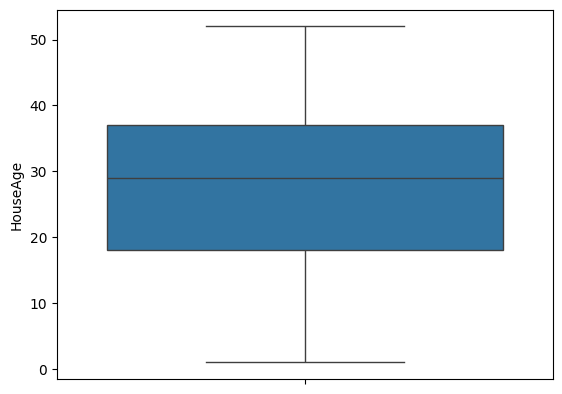

In [ ]:
sns.boxplot(IQR_cleaned_data['HouseAge'])
plt.show()

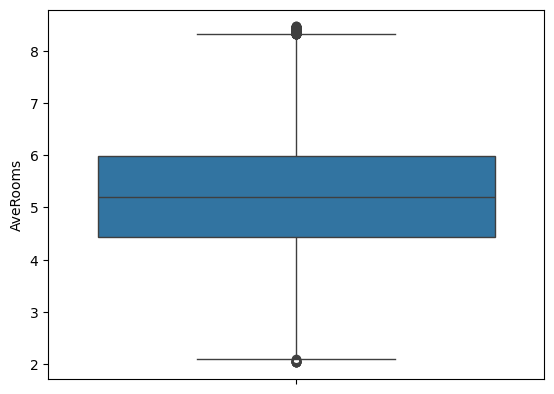

In [ ]:
sns.boxplot(IQR_cleaned_data['AveRooms'])
plt.show()

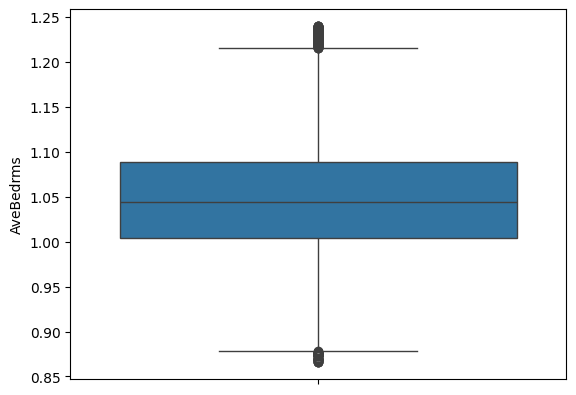

In [ ]:
sns.boxplot(IQR_cleaned_data['AveBedrms'])
plt.show()

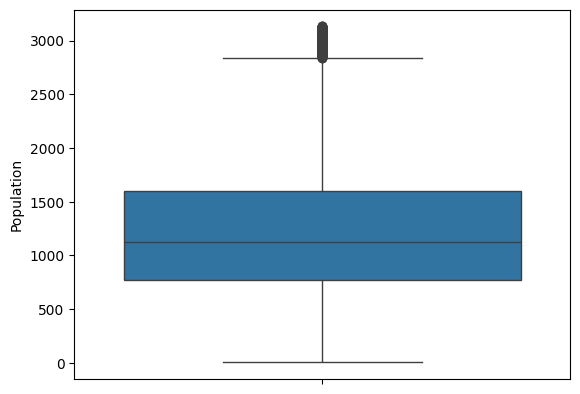

In [ ]:
sns.boxplot(IQR_cleaned_data['Population'])
plt.show()

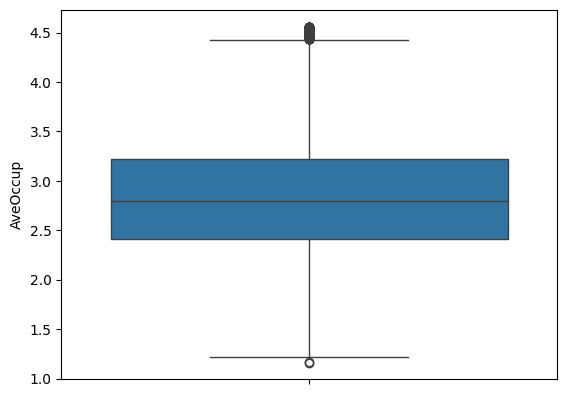

In [ ]:
sns.boxplot(IQR_cleaned_data['AveOccup'])
plt.show()

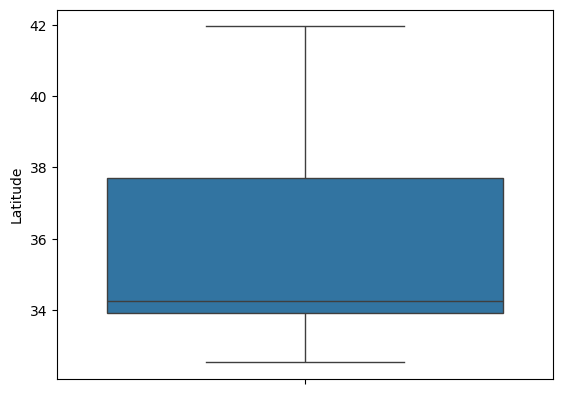

In [ ]:
sns.boxplot(IQR_cleaned_data['Latitude'])
plt.show()

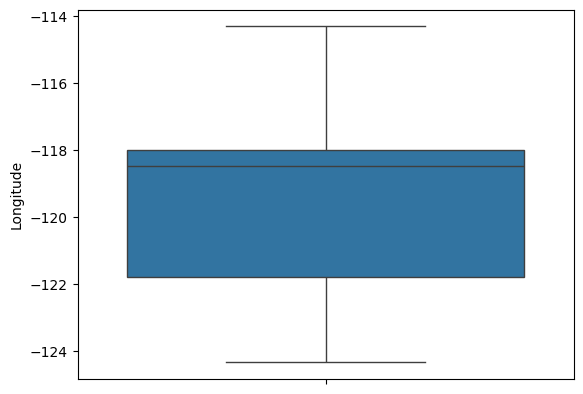

In [ ]:
sns.boxplot(IQR_cleaned_data['Longitude'])
plt.show()

Outliers where found By using Boxplot. By using IQR method outliers where removed.For ensuring the removal,redraw cleaned data

HANDLING SKEWNESS

In [ ]:
IQR_cleaned_data.skew()

,0
MedInc,0.568044
HouseAge,0.060331
AveRooms,0.195355
AveBedrms,0.247345
Population,0.692884
AveOccup,0.337301
Latitude,0.465953
Longitude,-0.297801


In [ ]:
IQR_cleaned_data.isnull().sum()

,0
MedInc,681
HouseAge,0
AveRooms,511
AveBedrms,1424
Population,1196
AveOccup,711
Latitude,0
Longitude,0


From the above data it is clear that no feature is skewed much.So we are not treating skewness.

In the given data,we are not performing encoding because all the features are numericals.

The given data have only 7 feature as independent variable,so feature selection is also avoiding

TRAIN TEST SPLIT


In [71]:
x=IQR_cleaned_data.drop('MedInc',axis=1)
y=IQR_cleaned_data[['MedInc']]
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
X_train.isnull().sum()

,0
HouseAge,0
AveRooms,411
AveBedrms,1156
Population,954
AveOccup,577
Latitude,0
Longitude,0


IMPUTATION

In [72]:
mean_imputer=SimpleImputer(strategy='mean')
X_train=mean_imputer.fit_transform(X_train)
X_test=mean_imputer.transform(X_test)
y_train=mean_imputer.fit_transform(y_train)
y_test=mean_imputer.transform(y_test)
X_train=pd.DataFrame(X_train,columns=x.columns)
X_test=pd.DataFrame(X_test,columns=x.columns)
X_train.isnull().sum()
X_test.isnull().sum()




,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


FEATURE SCALING

In [73]:
scaling=StandardScaler()
X_train=scaling.fit_transform(X_train)
X_test=scaling.transform(X_test)

REGRESSION ALGORITHMS

LINEAR REGRESSION

In [74]:
linear_regression_model=LinearRegression()
linear_regression_model.fit(X_train,y_train)

LinearRegression()

MODEL PREDICTION

In [75]:
y_predict_lr=linear_regression_model.predict(X_test)
y_predict_lr

array([[2.21233255],
       [3.10892278],
       [2.36592222],
       ...,
       [6.17503703],
       [3.40899062],
       [2.87812902]])

MODEL EVALUATION

In [76]:
MAE=mean_absolute_error(y_test,y_predict_lr)
MSE=mean_squared_error(y_test,y_predict_lr)
RMSE=np.sqrt(MSE)
R2=r2_score(y_test,y_predict_lr)
print('MAE:',MAE)
print('MSE:',MSE)
print('RMSE:',RMSE)
print('R2:',R2)


MAE: 0.7530610422091177
MSE: 1.001681330694895
RMSE: 1.0008403122850793
R2: 0.5188544343203746


WORKING : Linear regression try to find a linear relation between the independent feature(X) and dependent feature(y).Here the model learn the relation between X_train and y_train.After learning it generate predictions for X_test data.Since the data is continous regression models are best suit.Here the model is performing well upto 51%.

DECISION TREE

In [100]:
decision_tree_model=DecisionTreeRegressor(max_depth=5,min_samples_split=250,random_state=42)
decision_tree_model.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=5, min_samples_split=250, random_state=42)

MODEL PREDICTION

In [101]:
y_predict_dt=decision_tree_model.predict(X_test)
print(y_predict_dt)

[2.81758942 3.13268315 3.37332838 ... 5.66697603 3.75043294 2.81758942]


MODEL EVALUATION

In [102]:
MAE=mean_absolute_error(y_test,y_predict_dt)
MSE=mean_squared_error(y_test,y_predict_dt)
RMSE=np.sqrt(MSE)
R2=r2_score(y_test,y_predict_dt)
print('MAE:',MAE)
print('MSE:',MSE)
print('RMSE:',RMSE)
print('R2:',R2)

MAE: 0.7896522845575813
MSE: 1.0254278338990872
RMSE: 1.0126341066244446
R2: 0.5074480874443998


WORKING : A Decision tree regressor divides the data into small groups using conditions on the feature.Eventually, the tree reaches leaf nodes which made predictions.Here also model is only performing correctly upto 50%.

RANDOM FOREST REGRESSION

In [84]:
random_forest_model=RandomForestRegressor(random_state=42)
random_forest_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(random_state=42)

MODEL PREDICTION

In [85]:
y_predict_rf=random_forest_model.predict(X_test)
print(y_predict_rf)

[1.865017   2.28398403 3.980093   ... 6.10661969 3.0776     2.751493  ]


MODEL EVALUATION

In [89]:
MAE=mean_absolute_error(y_test,y_predict_rf)
MSE=mean_squared_error(y_test,y_predict_rf)
RMSE=np.sqrt(MSE)
R2=r2_score(y_test,y_predict_rf)
print('MAE:',MAE)
print('MSE:',MSE)
print('RMSE:',RMSE)
print('R2:',R2)

MAE: 0.5814700936156133
MSE: 0.6396280095123082
RMSE: 0.7997674721519425
R2: 0.6927623875670774


WORKING: Random forest is an ensemble method that combines many decision trees.Each tree produces a prediction,and the predictions are combined to obtain the final prediction.Here the model error is less in comparision to previous models.Because the correctness is upto 69%.

GRADIENT BOOSTING REGRESSOR

In [90]:
gradient_boosting_model=GradientBoost()
gradient_boosting_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


GradientBoostingRegressor()

MODEL PREDICTION

In [91]:
y_predict_gb=gradient_boosting_model.predict(X_test)
print(y_predict_gb)

[2.01965099 2.24366277 3.42261007 ... 6.15887096 3.38474337 2.9202824 ]


MODEL EVALUATION

In [92]:
MAE=mean_absolute_error(y_test,y_predict_gb)
MSE=mean_squared_error(y_test,y_predict_gb)
RMSE=np.sqrt(MSE)
R2=r2_score(y_test,y_predict_gb)
print('MAE:',MAE)
print('MSE:',MSE)
print('RMSE:',RMSE)
print('R2:',R2)

MAE: 0.628939770971357
MSE: 0.7195960140933583
RMSE: 0.84829005304398
R2: 0.6543507194832487


WORKING : Gradient boosting builds a tree sequentially.Each tree tries to improve the errors made by the previous trees.This model also serves a good performance of 65%

SVM

In [93]:
svm_model=SVR()
svm_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

MODEL PREDICTION

In [94]:
y_predict_svm=svm_model.predict(X_test)
print(y_predict_svm)

[1.64951369 2.59451484 3.50776742 ... 6.55041596 2.93100016 2.6317026 ]


MODEL EVALUTION


In [95]:
MAE=mean_absolute_error(y_test,y_predict_svm)
MSE=mean_squared_error(y_test,y_predict_svm)
RMSE=np.sqrt(MSE)
r2=r2_score(y_test,y_predict_svm)
print('MAE:',MAE)
print('MSE:',MSE)
print('RMSE:',RMSE)
print('R2:',R2)

MAE: 0.6439061227085525
MSE: 0.773939731890302
RMSE: 0.8797384451587312
R2: 0.6543507194832487


WORKING : SVM finds a decision boundary that seperates classes while maximizing the margin between them,using support vector to define that boundary.Here also model performance is similar as previous one.

CONCLUSION

From the above 5 regression models,best-performing algorithm is RANDOM FOREST and the worst-performing algorithm is DECISION TREE.it is clear from the metrix evalution.However we can improve the model performance by HYPERPARAMETER TUNING
